In [ ]:
# NORCE — LOAD TEST2, TEST3 AND TEST4 DATASETS

import pandas as pd

# Load datasets independently from local workspace paths
df_test2 = pd.read_csv("test2_subset.csv")
df_test3 = pd.read_csv("test3_subset.csv")
df_test4 = pd.read_csv("test4_subset.csv")

# Display dataset information
datasets = {
    "TEST2": df_test2,
    "TEST3": df_test3,
    "TEST4": df_test4
}

for name, dataset in datasets.items():
    print(f"\n{'=' * 55}")
    print(f"{name} DATASET")
    print(f"{'=' * 55}")
    print("Shape:", dataset.shape)
    print("Columns:", dataset.columns.tolist())
    print("\nData types:")
    print(dataset.dtypes)
    print("\nFirst five rows:")
    display(dataset.head())

print("\nAll three NORCE datasets loaded successfully.")


TEST2 DATASET
Shape: (32401, 5)
Columns: ['PS-I-MON', 'H-P1', 'O-P1', 'T-ELY-CH1', 'CV-mean']

Data types:
PS-I-MON     float64
H-P1         float64
O-P1         float64
T-ELY-CH1    float64
CV-mean      float64
dtype: object

First five rows:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
0,0.031763,-0.019139,-0.113484,16.4303,0.475429
1,0.031763,-0.028139,-0.110484,16.4283,0.475429
2,0.031763,-0.024139,-0.116484,16.4253,0.475429
3,0.031763,-0.025139,-0.108484,16.4173,0.475429
4,0.031763,-0.021139,-0.115484,16.4213,0.475429



TEST3 DATASET
Shape: (36000, 5)
Columns: ['PS-I-MON', 'H-P1', 'O-P1', 'T-ELY-CH1', 'CV-mean']

Data types:
PS-I-MON     float64
H-P1         float64
O-P1         float64
T-ELY-CH1    float64
CV-mean      float64
dtype: object

First five rows:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
0,0.07204,-0.01155,-0.078962,15.6267,-0.012345
1,0.07204,-0.01855,-0.080962,15.6317,-0.012345
2,0.07191,-0.01855,-0.087962,15.6257,-0.012345
3,0.07191,-0.01855,-0.087962,15.6317,-0.012345
4,0.07191,-0.01655,-0.093962,15.6287,-0.012345



TEST4 DATASET
Shape: (198001, 5)
Columns: ['PS-I-MON', 'H-P1', 'O-P1', 'T-ELY-CH1', 'CV-mean']

Data types:
PS-I-MON     float64
H-P1         float64
O-P1         float64
T-ELY-CH1    float64
CV-mean      float64
dtype: object

First five rows:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
0,0.080137,-0.041152,0.161889,16.2205,-0.032302
1,0.081137,-0.047152,0.163889,16.2268,-0.032302
2,0.081137,-0.039152,0.161889,16.2208,-0.032302
3,0.081137,-0.040152,0.169889,16.2208,-0.032302
4,0.081137,-0.037152,0.165889,16.2218,-0.032179



All three NORCE datasets loaded successfully.


In [ ]:
# NORCE — STAGE 1: MISSING-VALUE ASSESSMENT

import pandas as pd

datasets = {
    "TEST2": df_test2,
    "TEST3": df_test3,
    "TEST4": df_test4
}

missingness_results = []

for name, df in datasets.items():

    total_cells = df.size
    missing_cells = df.isna().sum().sum()

    print(f"\n{'='*65}")
    print(f"{name} — MISSING VALUE REPORT")
    print(f"{'='*65}")

    report = pd.DataFrame({
        "Missing_Count": df.isna().sum(),
        "Missing_Percentage": (df.isna().mean() * 100).round(4),
        "Present_Count": df.notna().sum()
    })

    print(report)

    print(f"\nTotal rows: {len(df)}")
    print(f"Total missing cells: {missing_cells}")
    print(f"Overall missing percentage: "
          f"{(missing_cells / total_cells * 100):.4f}%")
    print(f"Rows containing missing values: {df.isna().any(axis=1).sum()}")

    missingness_results.append({
        "Dataset": name,
        "Rows": len(df),
        "Total_Missing_Cells": missing_cells,
        "Missing_Percentage": round(missing_cells / total_cells * 100, 4),
        "Rows_With_Missing": int(df.isna().any(axis=1).sum())
    })

missingness_summary = pd.DataFrame(missingness_results)

print("\n\nNORCE — COMPARATIVE MISSINGNESS SUMMARY")
display(missingness_summary)


TEST2 — MISSING VALUE REPORT
           Missing_Count  Missing_Percentage  Present_Count
PS-I-MON             141              0.4352          32260
H-P1                 141              0.4352          32260
O-P1                 141              0.4352          32260
T-ELY-CH1            142              0.4383          32259
CV-mean              142              0.4383          32259

Total rows: 32401
Total missing cells: 707
Overall missing percentage: 0.4364%
Rows containing missing values: 142

TEST3 — MISSING VALUE REPORT
           Missing_Count  Missing_Percentage  Present_Count
PS-I-MON             312              0.8667          35688
H-P1                 312              0.8667          35688
O-P1                 312              0.8667          35688
T-ELY-CH1            314              0.8722          35686
CV-mean              311              0.8639          35689

Total rows: 36000
Total missing cells: 1561
Overall missing percentage: 0.8672%
Rows containing missing

,Dataset,Rows,Total_Missing_Cells,Missing_Percentage,Rows_With_Missing
0,TEST2,32401,707,0.4364,142
1,TEST3,36000,1561,0.8672,320
2,TEST4,198001,0,0.0000,0


In [ ]:
# NORCE — STAGE 1: MISSINGNESS PATTERN ANALYSIS

for name, df in datasets.items():

    print(f"\n{'='*65}")
    print(f"{name} — MISSINGNESS PATTERNS")
    print(f"{'='*65}")

    missing_mask = df.isna()

    # Rows with at least one missing value
    affected_rows = df.index[missing_mask.any(axis=1)]

    print("First affected row indices:",
          affected_rows[:15].tolist())

    print("Last affected row indices:",
          affected_rows[-15:].tolist())

    # Contiguous blocks of affected rows
    if len(affected_rows) > 0:

        groups = (affected_rows.to_series().diff() != 1).cumsum()

        blocks = (
            affected_rows.to_series()
            .groupby(groups)
            .agg(["min", "max", "count"])
            .reset_index(drop=True)
        )

        print("\nContiguous missing-row blocks:")
        display(blocks.head(20))

        print("Total contiguous blocks:", len(blocks))

    # Missingness combinations
    patterns = (
        missing_mask.astype(int)
        .astype(str)
        .agg("".join, axis=1)
        .value_counts()
    )

    print("\nMissingness patterns (1 = missing, 0 = present):")
    print(patterns.head(10))

    # Missingness at dataset boundaries
    print("\nFirst 10 rows — missingness:")
    display(missing_mask.head(10))

    print("\nLast 10 rows — missingness:")
    display(missing_mask.tail(10))


TEST2 — MISSINGNESS PATTERNS
First affected row indices: [18623, 18624, 18625, 18626, 18627, 18628, 18629, 18630, 18631, 18632, 18633, 18634, 18635, 18636, 18637]
Last affected row indices: [18750, 18751, 18752, 18753, 18754, 18755, 18756, 18757, 18758, 18759, 18760, 18761, 18762, 18763, 18764]

Contiguous missing-row blocks:


,min,max,count
0,18623,18764,142


Total contiguous blocks: 1

Missingness patterns (1 = missing, 0 = present):
00000    32259
11111      141
00011        1
Name: count, dtype: int64

First 10 rows — missingness:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
5,False,False,False,False,False
6,False,False,False,False,False
7,False,False,False,False,False
8,False,False,False,False,False
9,False,False,False,False,False



Last 10 rows — missingness:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
32391,False,False,False,False,False
32392,False,False,False,False,False
32393,False,False,False,False,False
32394,False,False,False,False,False
32395,False,False,False,False,False
32396,False,False,False,False,False
32397,False,False,False,False,False
32398,False,False,False,False,False
32399,False,False,False,False,False
32400,False,False,False,False,False


... (6 outputs left out)


TEST4 — MISSINGNESS PATTERNS
First affected row indices: []
Last affected row indices: []

Missingness patterns (1 = missing, 0 = present):
00000    198001
Name: count, dtype: int64

First 10 rows — missingness:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
5,False,False,False,False,False
6,False,False,False,False,False
7,False,False,False,False,False
8,False,False,False,False,False
9,False,False,False,False,False



Last 10 rows — missingness:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
197991,False,False,False,False,False
197992,False,False,False,False,False
197993,False,False,False,False,False
197994,False,False,False,False,False
197995,False,False,False,False,False
197996,False,False,False,False,False
197997,False,False,False,False,False
197998,False,False,False,False,False
197999,False,False,False,False,False
198000,False,False,False,False,False


In [ ]:
# NORCE — STAGE 2: DATA INTEGRITY AUDIT

for name, df in datasets.items():

    print(f"\n{'='*65}")
    print(f"{name} — DATA INTEGRITY")
    print(f"{'='*65}")

    print("Shape:", df.shape)

    # Exact duplicate rows
    duplicate_count = df.duplicated().sum()
    print("\nExact duplicate rows:", duplicate_count)

    # Constant columns
    unique_counts = df.nunique(dropna=True)

    print("\nUnique values per column:")
    print(unique_counts)

    constant_columns = unique_counts[unique_counts <= 1].index.tolist()
    print("Constant columns:", constant_columns)

    # Consecutive identical rows
    consecutive_duplicates = (
        df.eq(df.shift()).all(axis=1)
    ).sum()

    print("Consecutive identical rows:", consecutive_duplicates)

    # Row index integrity
    print("\nIndex starts at:", df.index.min())
    print("Index ends at:", df.index.max())
    print("Index is monotonic:", df.index.is_monotonic_increasing)
    print("Index is unique:", df.index.is_unique)

    # Numeric data integrity
    print("\nInfinite values per column:")
    print(
        df.isin([float("inf"), float("-inf")]).sum()
    )

    # First and last observations
    print("\nFirst 3 rows:")
    display(df.head(3))

    print("\nLast 3 rows:")
    display(df.tail(3))


TEST2 — DATA INTEGRITY
Shape: (32401, 5)

Exact duplicate rows: 193

Unique values per column:
PS-I-MON      6989
H-P1          8641
O-P1         10564
T-ELY-CH1    18353
CV-mean       3281
dtype: int64
Constant columns: []
Consecutive identical rows: 49

Index starts at: 0
Index ends at: 32400
Index is monotonic: True
Index is unique: True

Infinite values per column:
PS-I-MON     0
H-P1         0
O-P1         0
T-ELY-CH1    0
CV-mean      0
dtype: int64

First 3 rows:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
0,0.031763,-0.019139,-0.113484,16.4303,0.475429
1,0.031763,-0.028139,-0.110484,16.4283,0.475429
2,0.031763,-0.024139,-0.116484,16.4253,0.475429



Last 3 rows:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
32398,0.071545,-0.058839,-0.197275,63.1267,1.09680
32399,0.072545,-0.054839,-0.205275,63.1217,1.09666
32400,0.072545,-0.050839,-0.207275,63.1217,1.09766



TEST3 — DATA INTEGRITY
Shape: (36000, 5)

Exact duplicate rows: 328

Unique values per column:
PS-I-MON      7053
H-P1          9029
O-P1         16556
T-ELY-CH1    18741
CV-mean       2344
dtype: int64
Constant columns: []
Consecutive identical rows: 21

Index starts at: 0
Index ends at: 35999
Index is monotonic: True
Index is unique: True

Infinite values per column:
PS-I-MON     0
H-P1         0
O-P1         0
T-ELY-CH1    0
CV-mean      0
dtype: int64

First 3 rows:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
0,0.07204,-0.01155,-0.078962,15.6267,-0.012345
1,0.07204,-0.01855,-0.080962,15.6317,-0.012345
2,0.07191,-0.01855,-0.087962,15.6257,-0.012345


... (2 outputs left out)


TEST4 — DATA INTEGRITY
Shape: (198001, 5)

Exact duplicate rows: 61

Unique values per column:
PS-I-MON     19208
H-P1         12454
O-P1         22122
T-ELY-CH1    54459
CV-mean       4711
dtype: int64
Constant columns: []
Consecutive identical rows: 60

Index starts at: 0
Index ends at: 198000
Index is monotonic: True
Index is unique: True

Infinite values per column:
PS-I-MON     0
H-P1         0
O-P1         0
T-ELY-CH1    0
CV-mean      0
dtype: int64

First 3 rows:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
0,0.080137,-0.041152,0.161889,16.2205,-0.032302
1,0.081137,-0.047152,0.163889,16.2268,-0.032302
2,0.081137,-0.039152,0.161889,16.2208,-0.032302



Last 3 rows:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
197998,0.074175,-0.077394,-0.201398,58.6438,1.05046
197999,0.074175,-0.087393,-0.206398,58.6468,1.05046
198000,0.074175,-0.073394,-0.203398,58.6468,1.04946


In [ ]:
# NORCE — STAGE 2: DUPLICATE INVESTIGATION

for name, df in datasets.items():

    print(f"\n{'='*65}")
    print(f"{name} — DUPLICATE INVESTIGATION")
    print(f"{'='*65}")

    # Identify all rows participating in exact duplicate groups
    duplicate_mask = df.duplicated(keep=False)
    duplicate_rows = df.loc[duplicate_mask].copy()

    print("Rows participating in duplicate groups:",
          duplicate_mask.sum())

    print("Distinct duplicated row patterns:",
          df.loc[df.duplicated(keep="first")].drop_duplicates().shape[0])

    # Inspect most frequent duplicated patterns
    if not duplicate_rows.empty:
        frequency = (
            duplicate_rows.value_counts(dropna=False)
            .rename("Occurrences")
            .reset_index()
            .sort_values("Occurrences", ascending=False)
        )

        print("\nTop 10 duplicated patterns:")
        display(frequency.head(10))

        print("\nFirst 15 duplicate row indices:")
        print(df.index[duplicate_mask][:15].tolist())

    # Compare duplicate rows with missingness
    missing_rows = df.isna().any(axis=1)

    print("\nDuplicate rows containing missing values:",
          (duplicate_mask & missing_rows).sum())

    print("Duplicate rows without missing values:",
          (duplicate_mask & ~missing_rows).sum())

    # Check consecutive identical observations separately
    consecutive_mask = df.eq(df.shift()).all(axis=1)

    print("\nConsecutive identical row indices:")
    print(df.index[consecutive_mask][:20].tolist())


TEST2 — DUPLICATE INVESTIGATION
Rows participating in duplicate groups: 247
Distinct duplicated row patterns: 54

Top 10 duplicated patterns:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean,Occurrences
0,NaN,NaN,NaN,NaN,NaN,141
1,0.030841,-0.019016,-0.110681,16.3735,0.461959,2
2,0.031050,-0.015221,-0.112844,16.4122,0.473950,2
3,0.031075,-0.023335,-0.115991,16.3899,0.450954,2
4,0.031164,-0.011361,-0.118803,16.3918,0.452760,2
5,0.030997,-0.017795,-0.112975,16.4186,0.447997,2
6,0.031529,-0.025114,-0.115722,16.3686,0.461302,2
7,0.031529,-0.024114,-0.106722,16.3664,0.461302,2
8,0.031555,-0.023524,-0.115311,16.3991,0.469844,2
9,0.031581,-0.022179,-0.103788,16.3613,0.458838,2



First 15 duplicate row indices:
[52, 53, 177, 178, 190, 191, 659, 660, 814, 815, 834, 835, 902, 903, 1048]

Duplicate rows containing missing values: 141
Duplicate rows without missing values: 106

Consecutive identical row indices:
[53, 178, 191, 660, 815, 835, 903, 1130, 1590, 1660, 1745, 1765, 2188, 2200, 2693, 2885, 2896, 3113, 3525, 3545]

TEST3 — DUPLICATE INVESTIGATION
Rows participating in duplicate groups: 352
Distinct duplicated row patterns: 24

Top 10 duplicated patterns:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean,Occurrences
0,NaN,NaN,NaN,NaN,NaN,306
1,0.071154,-0.015565,-0.082626,15.6277,-0.011975,2
2,0.071154,-0.013254,-0.080667,15.6395,-0.011345,2
3,0.071154,-0.014254,-0.082012,15.6419,-0.012509,2
4,0.071910,-0.022444,-0.081684,15.6471,-0.012564,2
5,0.071910,-0.020721,-0.082962,15.6248,-0.012345,2
6,0.071910,-0.019721,-0.086471,15.6239,-0.012031,2
7,0.071831,-0.021788,-0.081799,15.6329,-0.012811,2
8,0.071910,-0.018721,-0.083962,15.6353,-0.012304,2
9,0.072066,-0.013624,-0.081561,15.6597,-0.011893,2



First 15 duplicate row indices:
[9, 10, 19, 20, 84, 85, 135, 136, 504, 505, 589, 590, 962, 963, 1132]

Duplicate rows containing missing values: 306
Duplicate rows without missing values: 46

Consecutive identical row indices:
[10, 20, 85, 136, 505, 590, 963, 1133, 1310, 1353, 1395, 1610, 1655, 1685, 1930, 2154, 2280, 3625, 4610, 4790]

TEST4 — DUPLICATE INVESTIGATION
Rows participating in duplicate groups: 122
Distinct duplicated row patterns: 61

Top 10 duplicated patterns:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean,Occurrences
0,0.032039,-0.043037,-0.134718,16.4499,-0.032467,2
1,0.032206,-0.038555,0.159964,16.3090,-0.032631,2
2,0.032206,-0.037555,0.158964,16.3176,-0.032467,2
3,0.032247,-0.040358,-0.140398,16.5108,-0.032343,2
4,0.032544,-0.033326,0.163128,16.4066,-0.032426,2
5,0.032544,-0.033121,0.166128,16.3987,-0.032343,2
6,0.032544,-0.026326,0.169636,16.4013,-0.032426,2
7,0.073560,-0.081639,-0.208684,58.2522,1.136020,2
8,0.078434,-0.035828,0.167537,16.2476,-0.032302,2
9,0.079340,0.080282,0.171192,16.2613,-0.032385,2



First 15 duplicate row indices:
[174, 175, 294, 295, 583, 584, 619, 620, 959, 960, 1039, 1040, 1049, 1050, 1234]

Duplicate rows containing missing values: 0
Duplicate rows without missing values: 122

Consecutive identical row indices:
[175, 295, 584, 620, 960, 1040, 1050, 1235, 1550, 1675, 2565, 2825, 2990, 3595, 3625, 3985, 11545, 37395, 72825, 82820]


In [ ]:
# NORCE — STAGE 2: SEQUENCE AND NUMERICAL CONSISTENCY

import numpy as np
import pandas as pd

for name, df in datasets.items():

    print(f"\n{'='*65}")
    print(f"{name} — SEQUENCE CONSISTENCY")
    print(f"{'='*65}")

    for col in df.columns:

        series = df[col]

        # Differences between consecutive available rows
        differences = series.diff()

        print(f"\nColumn: {col}")
        print("Minimum:", series.min())
        print("Maximum:", series.max())
        print("Mean:", series.mean())
        print("Standard deviation:", series.std())

        print("Maximum absolute consecutive change:",
              differences.abs().max())

        print("99th percentile absolute change:",
              differences.abs().quantile(0.99))

        # Largest changes and their row positions
        largest_changes = differences.abs().nlargest(5)

        print("\nFive largest absolute changes:")
        for idx, value in largest_changes.items():
            print(
                f"Row {idx}: change={value:.6f}, "
                f"previous={series.iloc[idx-1] if idx > 0 else np.nan}, "
                f"current={series.iloc[idx]}"
            )


TEST2 — SEQUENCE CONSISTENCY

Column: PS-I-MON
Minimum: -0.4300029999999999
Maximum: 18.0279
Mean: 4.78980386232486
Standard deviation: 5.153648524601035
Maximum absolute consecutive change: 1.3550000000000004
99th percentile absolute change: 0.09642999999999938

Five largest absolute changes:
Row 16986: change=1.355000, previous=16.6069, current=17.9619
Row 10600: change=1.080005, previous=0.108205, current=1.18821
Row 14595: change=1.078995, previous=1.18615, current=0.107155
Row 15948: change=1.074999, previous=0.104841, current=1.17984
Row 29031: change=1.058001, previous=1.1656799999999998, current=0.107679

Column: H-P1
Minimum: -0.0876236
Maximum: 34.5074
Mean: 7.292237625048668
Standard deviation: 11.298674167614186
Maximum absolute consecutive change: 1.8599999999999994
99th percentile absolute change: 0.1039999999999992

Five largest absolute changes:
Row 28264: change=1.860000, previous=32.884, current=31.024
Row 28263: change=1.600000, previous=34.484, current=32.884
Row 2

In [ ]:
# NORCE — STAGE 3: SENSOR AND DATA-QUALITY ASSESSMENT

import numpy as np
import pandas as pd

quality_reports = []

for name, df in datasets.items():

    print(f"\n{'='*70}")
    print(f"{name} — SENSOR QUALITY REPORT")
    print(f"{'='*70}")

    report = []

    for col in df.columns:

        s = df[col].dropna()

        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outlier_mask = (s < lower_bound) | (s > upper_bound)

        result = {
            "Dataset": name,
            "Variable": col,
            "Minimum": s.min(),
            "Maximum": s.max(),
            "Mean": s.mean(),
            "Median": s.median(),
            "Std": s.std(),
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Negative_Count": (s < 0).sum(),
            "Zero_Count": (s == 0).sum(),
            "IQR_Outlier_Count": outlier_mask.sum(),
            "IQR_Outlier_Percentage": (
                outlier_mask.mean() * 100
            )
        }

        report.append(result)
        quality_reports.append(result)

    report_df = pd.DataFrame(report)

    display(
        report_df.round(5)
    )

quality_summary = pd.DataFrame(quality_reports)

print("\nNORCE — COMBINED SENSOR QUALITY SUMMARY")
display(quality_summary.round(5))


TEST2 — SENSOR QUALITY REPORT


,Dataset,Variable,Minimum,Maximum,Mean,Median,Std,Q1,Q3,IQR,Negative_Count,Zero_Count,IQR_Outlier_Count,IQR_Outlier_Percentage
0,TEST2,PS-I-MON,-0.43000,18.02790,4.78980,3.63741,5.15365,0.09689,8.06963,7.97275,11,0,0,0.00000
1,TEST2,H-P1,-0.08762,34.50740,7.29224,-0.04271,11.29867,-0.06084,14.38930,14.45014,20891,0,0,0.00000
2,TEST2,O-P1,-0.22734,33.97730,7.83850,-0.11679,12.43991,-0.17462,19.64510,19.81972,21613,0,0,0.00000
3,TEST2,T-ELY-CH1,16.34090,81.79530,68.94888,79.48230,22.25518,72.43910,80.45370,8.01460,0,0,5479,16.98441
4,TEST2,CV-mean,0.43386,1.86575,1.26794,1.51524,0.53086,0.69440,1.75133,1.05693,0,0,0,0.00000



TEST3 — SENSOR QUALITY REPORT


,Dataset,Variable,Minimum,Maximum,Mean,Median,Std,Q1,Q3,IQR,Negative_Count,Zero_Count,IQR_Outlier_Count,IQR_Outlier_Percentage
0,TEST3,PS-I-MON,0.07068,6.14315,4.92039,6.10153,2.36838,6.06012,6.12753,0.06741,0,0,7274,20.38220
1,TEST3,H-P1,-0.07401,39.45560,19.20674,19.33270,14.85341,-0.01330,34.37152,34.38482,9884,0,0,0.00000
2,TEST3,O-P1,-0.19097,41.33240,21.12895,24.30700,15.33917,4.03842,34.40660,30.36818,8386,0,0,0.00000
3,TEST3,T-ELY-CH1,15.61400,81.76100,74.12765,79.73105,17.30251,79.09810,80.57837,1.48027,0,0,4943,13.85137
4,TEST3,CV-mean,-0.01544,1.78738,1.42774,1.69811,0.62178,1.59799,1.75582,0.15783,3133,0,6639,18.60237



TEST4 — SENSOR QUALITY REPORT


,Dataset,Variable,Minimum,Maximum,Mean,Median,Std,Q1,Q3,IQR,Negative_Count,Zero_Count,IQR_Outlier_Count,IQR_Outlier_Percentage
0,TEST4,PS-I-MON,-0.46104,15.07640,5.45178,5.13159,1.76937,5.12668,5.56184,0.43516,12,0,21401,10.80853
1,TEST4,H-P1,-0.09837,39.63170,23.12769,19.47230,12.70003,19.42840,39.50300,20.07460,26047,0,0,0.00000
2,TEST4,O-P1,-0.22265,40.99420,23.63987,19.67500,13.13372,19.65740,39.97350,20.31610,25030,0,0,0.00000
3,TEST4,T-ELY-CH1,16.21430,81.94770,74.58080,72.83900,7.36302,71.54360,79.58330,8.03970,0,0,3479,1.75706
4,TEST4,CV-mean,-0.04012,1.81602,1.71241,1.75728,0.27659,1.75465,1.77580,0.02115,4568,0,20435,10.32065



NORCE — COMBINED SENSOR QUALITY SUMMARY


,Dataset,Variable,Minimum,Maximum,Mean,Median,Std,Q1,Q3,IQR,Negative_Count,Zero_Count,IQR_Outlier_Count,IQR_Outlier_Percentage
0,TEST2,PS-I-MON,-0.43000,18.02790,4.78980,3.63741,5.15365,0.09689,8.06963,7.97275,11,0,0,0.00000
1,TEST2,H-P1,-0.08762,34.50740,7.29224,-0.04271,11.29867,-0.06084,14.38930,14.45014,20891,0,0,0.00000
2,TEST2,O-P1,-0.22734,33.97730,7.83850,-0.11679,12.43991,-0.17462,19.64510,19.81972,21613,0,0,0.00000
3,TEST2,T-ELY-CH1,16.34090,81.79530,68.94888,79.48230,22.25518,72.43910,80.45370,8.01460,0,0,5479,16.98441
4,TEST2,CV-mean,0.43386,1.86575,1.26794,1.51524,0.53086,0.69440,1.75133,1.05693,0,0,0,0.00000
5,TEST3,PS-I-MON,0.07068,6.14315,4.92039,6.10153,2.36838,6.06012,6.12753,0.06741,0,0,7274,20.38220
6,TEST3,H-P1,-0.07401,39.45560,19.20674,19.33270,14.85341,-0.01330,34.37152,34.38482,9884,0,0,0.00000
7,TEST3,O-P1,-0.19097,41.33240,21.12895,24.30700,15.33917,4.03842,34.40660,30.36818,8386,0,0,0.00000
8,TEST3,T-ELY-CH1,15.61400,81.76100,74.12765,79.73105,17.30251,79.09810,80.57837,1.48027,0,0,4943,13.85137
9,TEST3,CV-mean,-0.01544,1.78738,1.42774,1.69811,0.62178,1.59799,1.75582,0.15783,3133,0,6639,18.60237


In [ ]:
# NORCE — STAGE 3: OPERATING REGIME DISTRIBUTION

import pandas as pd
import numpy as np

for name, df in datasets.items():

    print(f"\n{'='*65}")
    print(f"{name} — OPERATING REGIME ANALYSIS")
    print(f"{'='*65}")

    valid = df.dropna()

    # PS-I-MON operating regions
    ps = valid["PS-I-MON"]

    print("\nPS-I-MON distribution:")
    print("Below 0.5:", (ps < 0.5).sum())
    print("0.5 to 3:", ((ps >= 0.5) & (ps < 3)).sum())
    print("3 and above:", (ps >= 3).sum())

    # Temperature operating regions
    temp = valid["T-ELY-CH1"]

    print("\nTemperature distribution:")
    print("Below 60:", (temp < 60).sum())
    print("60 to 70:", ((temp >= 60) & (temp < 70)).sum())
    print("70 to 80:", ((temp >= 70) & (temp < 80)).sum())
    print("80 and above:", (temp >= 80).sum())

    # CV-mean distribution
    cv = valid["CV-mean"]

    print("\nCV-mean distribution:")
    print("Negative:", (cv < 0).sum())
    print("0 to 0.5:", ((cv >= 0) & (cv < 0.5)).sum())
    print("0.5 to 1:", ((cv >= 0.5) & (cv < 1)).sum())
    print("1 to 1.5:", ((cv >= 1) & (cv < 1.5)).sum())
    print("1.5 and above:", (cv >= 1.5).sum())

    # Correlation matrix
    print("\nCorrelation matrix:")
    display(valid.corr().round(3))


TEST2 — OPERATING REGIME ANALYSIS

PS-I-MON distribution:
Below 0.5: 15323
0.5 to 3: 598
3 and above: 16338

Temperature distribution:
Below 60: 5464
60 to 70: 2014
70 to 80: 13233
80 and above: 11548

CV-mean distribution:
Negative: 0
0 to 0.5: 5512
0.5 to 1: 5088
1 to 1.5: 5487
1.5 and above: 16172

Correlation matrix:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
PS-I-MON,1.000,0.348,0.336,0.462,0.812
H-P1,0.348,1.000,0.992,0.325,0.600
O-P1,0.336,0.992,1.000,0.321,0.591
T-ELY-CH1,0.462,0.325,0.321,1.000,0.711
CV-mean,0.812,0.600,0.591,0.711,1.000



TEST3 — OPERATING REGIME ANALYSIS

PS-I-MON distribution:
Below 0.5: 6737
0.5 to 3: 145
3 and above: 28798

Temperature distribution:
Below 60: 3413
60 to 70: 836
70 to 80: 16715
80 and above: 14716

CV-mean distribution:
Negative: 3124
0 to 0.5: 2528
0.5 to 1: 4
1 to 1.5: 1254
1.5 and above: 28770

Correlation matrix:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
PS-I-MON,1.000,0.648,0.690,0.701,0.931
H-P1,0.648,1.000,0.993,0.444,0.653
O-P1,0.690,0.993,1.000,0.474,0.689
T-ELY-CH1,0.701,0.444,0.474,1.000,0.768
CV-mean,0.931,0.653,0.689,0.768,1.000



TEST4 — OPERATING REGIME ANALYSIS

PS-I-MON distribution:
Below 0.5: 6207
0.5 to 3: 586
3 and above: 191208

Temperature distribution:
Below 60: 3518
60 to 70: 750
70 to 80: 158741
80 and above: 34992

CV-mean distribution:
Negative: 4568
0 to 0.5: 75
0.5 to 1: 2
1 to 1.5: 2020
1.5 and above: 191336

Correlation matrix:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
PS-I-MON,1.000,-0.026,-0.023,0.497,0.541
H-P1,-0.026,1.000,0.998,0.495,0.377
O-P1,-0.023,0.998,1.000,0.498,0.374
T-ELY-CH1,0.497,0.495,0.498,1.000,0.644
CV-mean,0.541,0.377,0.374,0.644,1.000



TEST2 — SENSOR RELATIONSHIP PLOTS


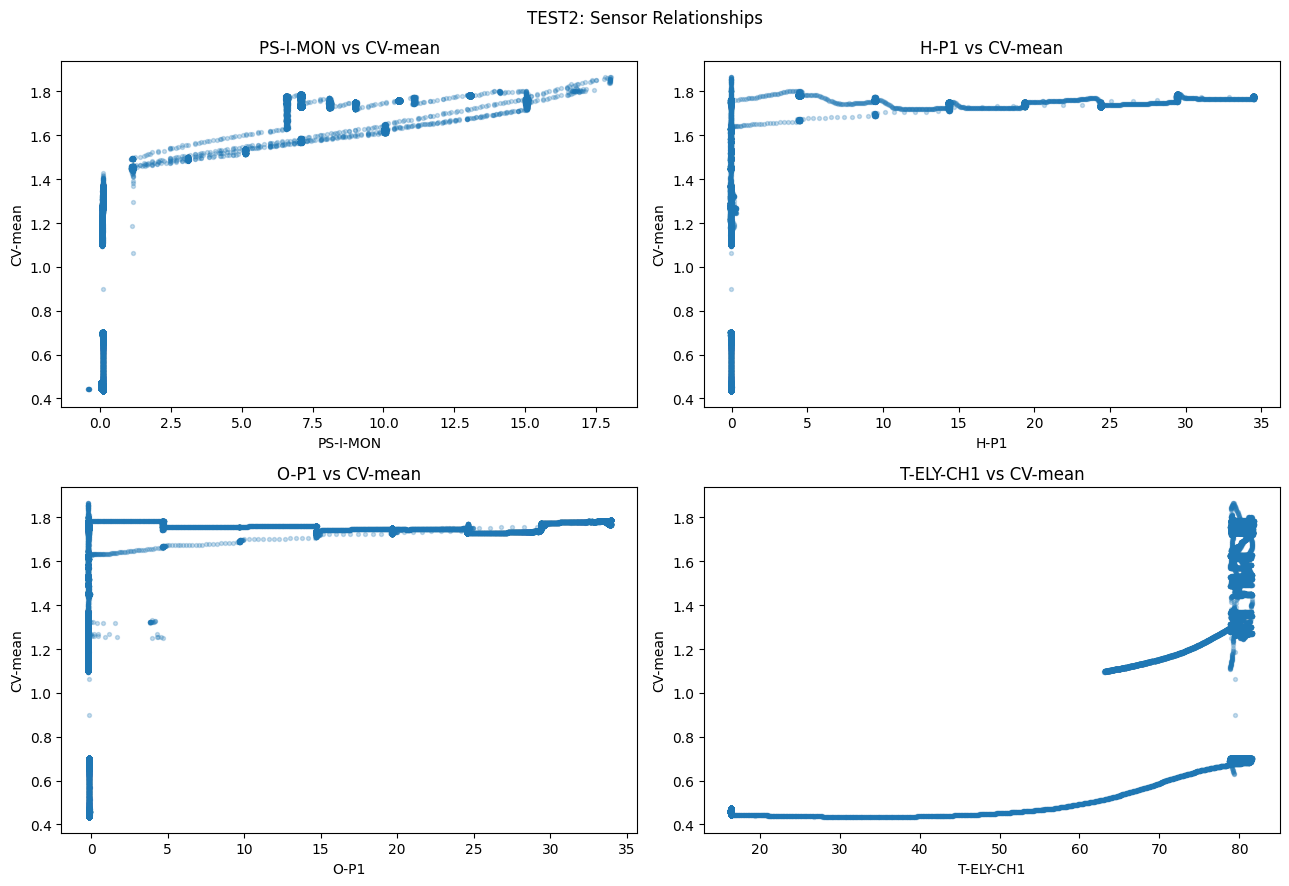

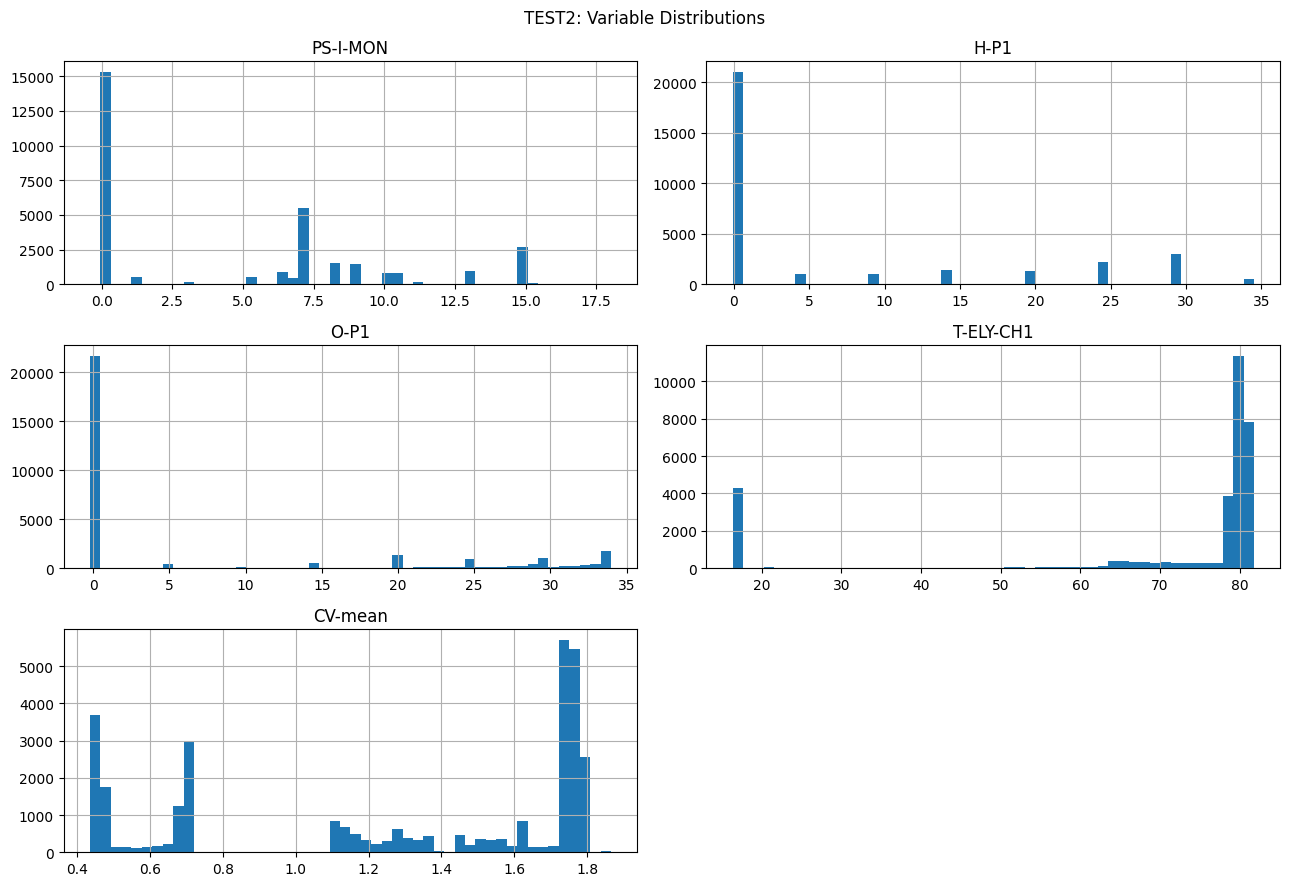


TEST3 — SENSOR RELATIONSHIP PLOTS


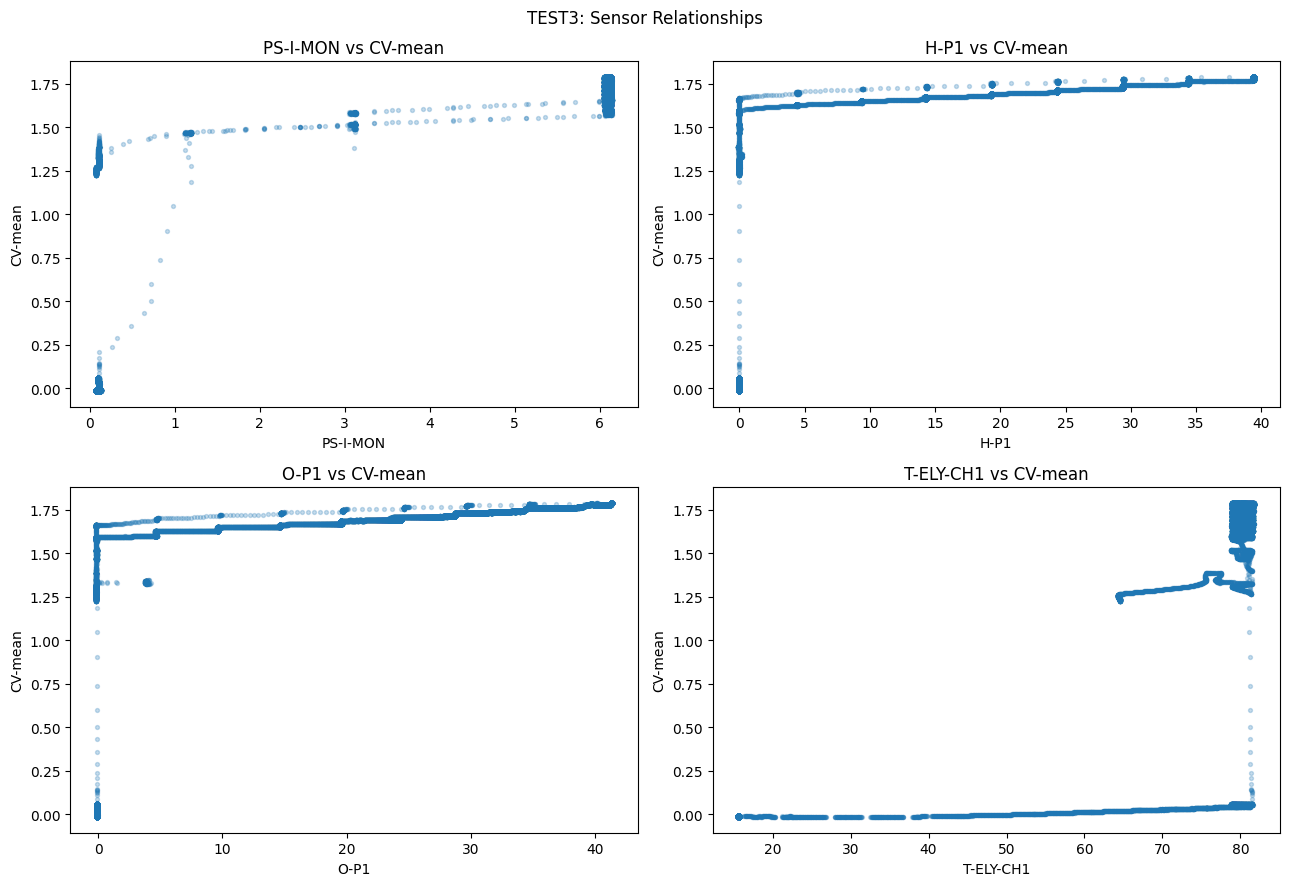

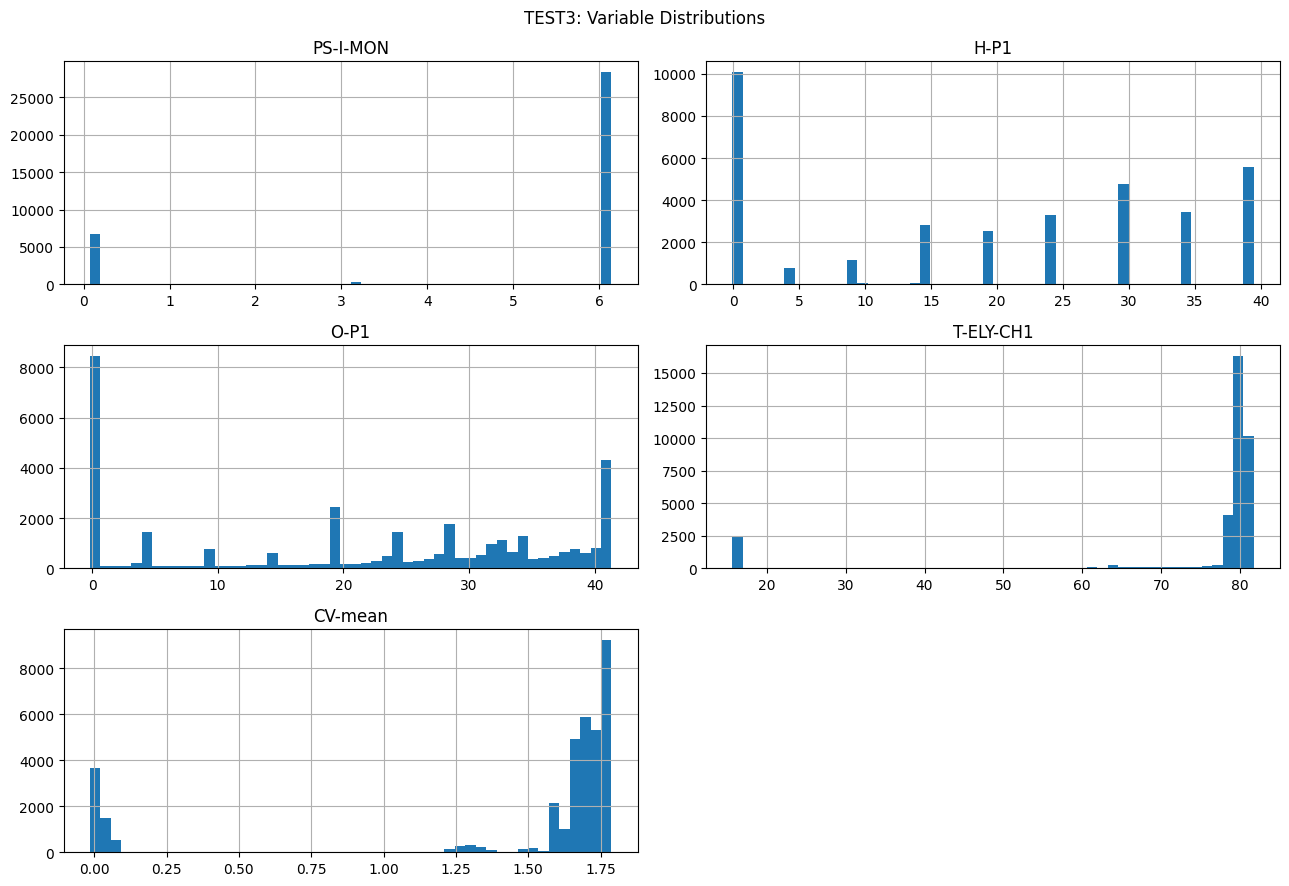


TEST4 — SENSOR RELATIONSHIP PLOTS


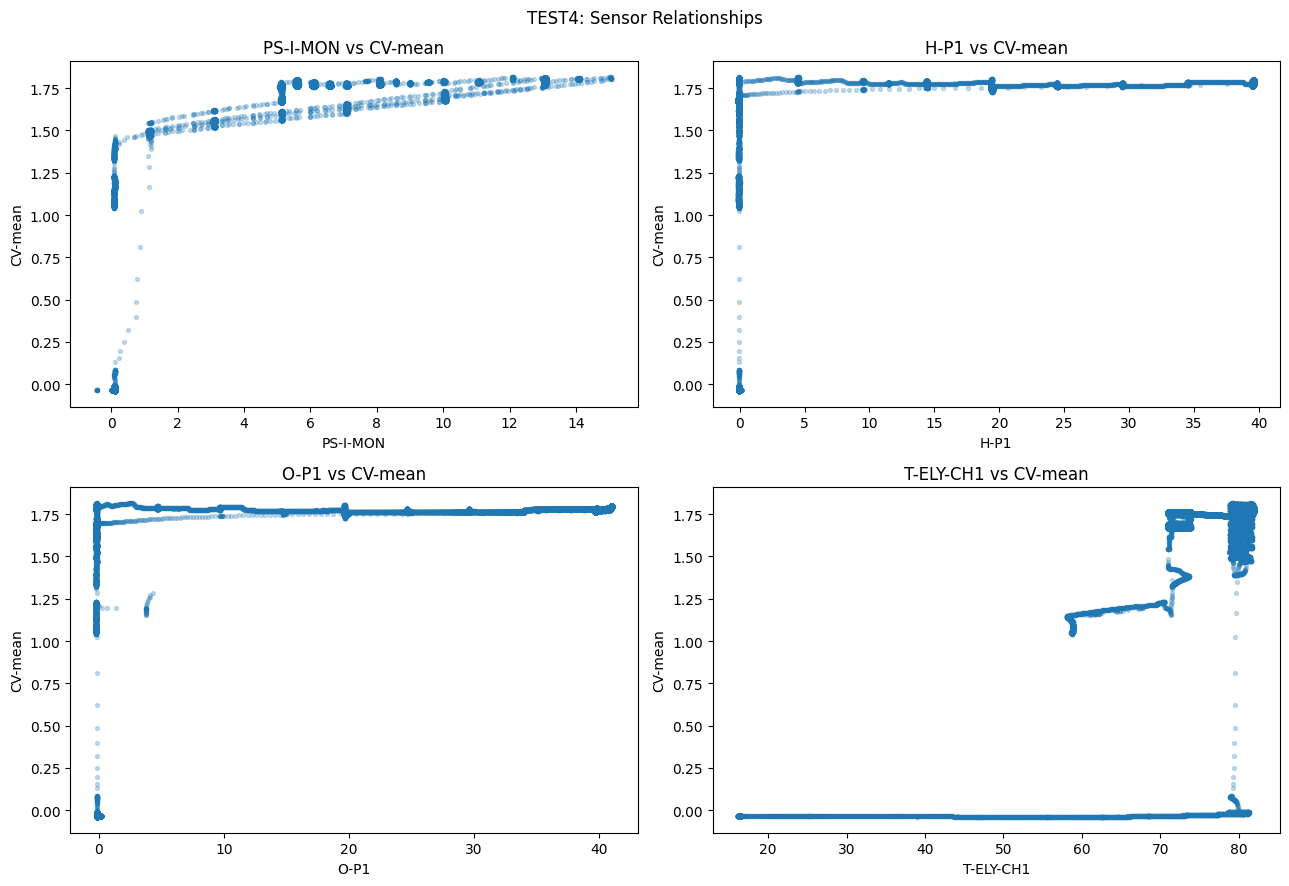

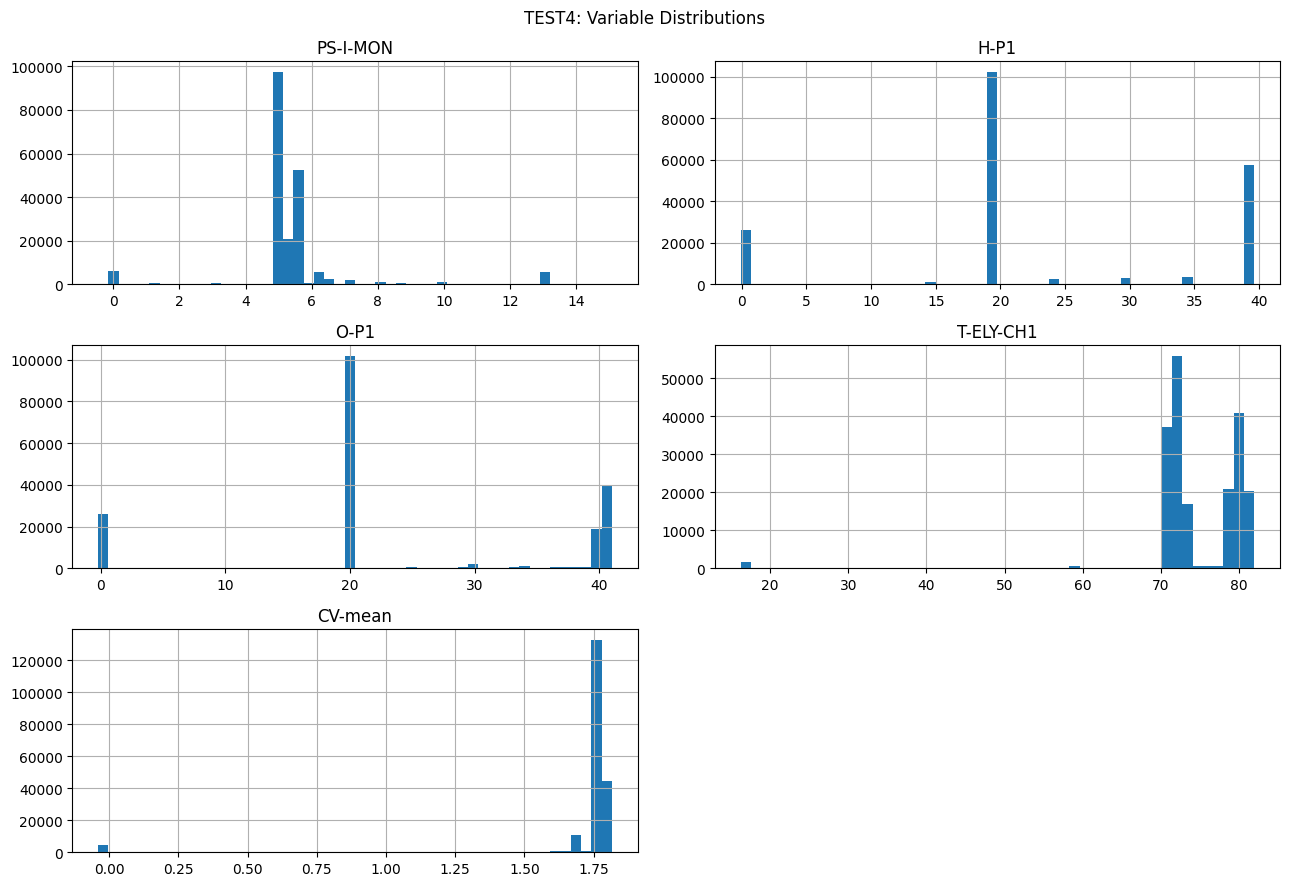

In [ ]:
# NORCE — STAGE 3: SENSOR RELATIONSHIP VISUALIZATION

import matplotlib.pyplot as plt
import seaborn as sns

for name, df in datasets.items():

    print(f"\n{'='*65}")
    print(f"{name} — SENSOR RELATIONSHIP PLOTS")
    print(f"{'='*65}")

    plot_df = df.dropna().copy()

    # Scatterplots against candidate target
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))

    features = [
        "PS-I-MON",
        "H-P1",
        "O-P1",
        "T-ELY-CH1"
    ]

    for ax, feature in zip(axes.flatten(), features):

        ax.scatter(
            plot_df[feature],
            plot_df["CV-mean"],
            alpha=0.25,
            s=8
        )

        ax.set_xlabel(feature)
        ax.set_ylabel("CV-mean")
        ax.set_title(f"{feature} vs CV-mean")

    plt.suptitle(f"{name}: Sensor Relationships")
    plt.tight_layout()
    plt.show()

    # Distribution plots
    plot_df[features + ["CV-mean"]].hist(
        bins=50,
        figsize=(13, 9)
    )

    plt.suptitle(f"{name}: Variable Distributions")
    plt.tight_layout()
    plt.show()

In [ ]:
# NORCE — STAGE 3 FINAL DIAGNOSTIC
# Correlations within PS-I-MON operating regimes

regimes = {
    "LOW (<0.5)": lambda x: x < 0.5,
    "INTERMEDIATE (0.5–3)": lambda x: (x >= 0.5) & (x < 3),
    "HIGH (>=3)": lambda x: x >= 3
}

for name, df in datasets.items():

    print(f"\n{'='*70}")
    print(f"{name} — WITHIN-REGIME CORRELATIONS")
    print(f"{'='*70}")

    for regime_name, condition in regimes.items():

        subset = df.loc[condition(df["PS-I-MON"])].dropna()

        print(f"\n{regime_name}")
        print("Observations:", len(subset))

        if len(subset) < 3:
            print("Insufficient observations")
            continue

        print(
            subset[
                ["PS-I-MON", "H-P1", "O-P1",
                 "T-ELY-CH1", "CV-mean"]
            ].corr().round(3)
        )


TEST2 — WITHIN-REGIME CORRELATIONS

LOW (<0.5)
Observations: 15323
           PS-I-MON   H-P1   O-P1  T-ELY-CH1  CV-mean
PS-I-MON      1.000 -0.502 -0.004      0.746    0.345
H-P1         -0.502  1.000  0.303     -0.635   -0.411
O-P1         -0.004  0.303  1.000     -0.078   -0.156
T-ELY-CH1     0.746 -0.635 -0.078      1.000    0.663
CV-mean       0.345 -0.411 -0.156      0.663    1.000

INTERMEDIATE (0.5–3)
Observations: 598
           PS-I-MON   H-P1   O-P1  T-ELY-CH1  CV-mean
PS-I-MON      1.000 -0.012 -0.189     -0.299    0.440
H-P1         -0.012  1.000 -0.464     -0.001   -0.042
O-P1         -0.189 -0.464  1.000      0.174   -0.438
T-ELY-CH1    -0.299 -0.001  0.174      1.000    0.026
CV-mean       0.440 -0.042 -0.438      0.026    1.000

HIGH (>=3)
Observations: 16338
           PS-I-MON   H-P1   O-P1  T-ELY-CH1  CV-mean
PS-I-MON      1.000 -0.657 -0.666      0.025    0.325
H-P1         -0.657  1.000  0.987      0.009    0.463
O-P1         -0.666  0.987  1.000      0.002    0.

In [ ]:
# NORCE — H-P1 / O-P1 DIFFERENTIAL ANALYSIS

for name, df in datasets.items():

    print(f"\n{'='*70}")
    print(f"{name} — PRESSURE DIFFERENTIAL ANALYSIS")
    print(f"{'='*70}")

    temp_df = df[
        ["PS-I-MON", "H-P1", "O-P1", "CV-mean"]
    ].copy()

    temp_df["Pressure_Difference"] = (
        temp_df["H-P1"] - temp_df["O-P1"]
    )

    diff = temp_df["Pressure_Difference"].dropna()

    print("\nPressure difference statistics:")
    print(diff.describe().round(5))

    print("\nAbsolute difference:")
    print(diff.abs().describe().round(5))

    print("\nCorrelation with CV-mean:")
    print(
        temp_df[
            ["Pressure_Difference", "CV-mean"]
        ].corr().round(4)
    )

    print("\nPressure difference by current regime:")

    temp_df["Current_Regime"] = pd.cut(
        temp_df["PS-I-MON"],
        bins=[-np.inf, 0.5, 3, np.inf],
        labels=["LOW", "INTERMEDIATE", "HIGH"],
        right=False
    )

    print(
        temp_df.groupby(
            "Current_Regime",
            observed=False
        )["Pressure_Difference"]
        .agg(["count", "mean", "std", "min", "max"])
        .round(5)
    )


TEST2 — PRESSURE DIFFERENTIAL ANALYSIS

Pressure difference statistics:
count    32260.00000
mean        -0.54627
std          1.86899
min         -5.36920
25%         -0.25920
50%          0.08195
75%          0.11755
max          4.90295
Name: Pressure_Difference, dtype: float64

Absolute difference:
count    32260.00000
mean         1.01388
std          1.66240
min          0.00029
25%          0.08825
50%          0.12250
75%          0.84760
max          5.36920
Name: Pressure_Difference, dtype: float64

Correlation with CV-mean:
                     Pressure_Difference  CV-mean
Pressure_Difference               1.0000  -0.3076
CV-mean                          -0.3076   1.0000

Pressure difference by current regime:
                count     mean      std      min      max
Current_Regime                                           
LOW             15323  0.08986  0.16041 -4.56736  0.49864
INTERMEDIATE      598  0.10080  0.03687  0.01833  0.15454
HIGH            16339 -1.16651  2.46

In [ ]:
# NORCE — WITHIN-REGIME PRESSURE DIFFERENTIAL vs CV-MEAN

for name, df in datasets.items():

    temp_df = df[
        ["PS-I-MON", "H-P1", "O-P1", "CV-mean"]
    ].copy()

    temp_df["Pressure_Difference"] = (
        temp_df["H-P1"] - temp_df["O-P1"]
    )

    temp_df["Current_Regime"] = pd.cut(
        temp_df["PS-I-MON"],
        bins=[-np.inf, 0.5, 3, np.inf],
        labels=["LOW", "INTERMEDIATE", "HIGH"],
        right=False
    )

    print(f"\n{'='*65}")
    print(f"{name} — WITHIN-REGIME CORRELATIONS")
    print(f"{'='*65}")

    for regime in ["LOW", "INTERMEDIATE", "HIGH"]:

        subset = temp_df[
            temp_df["Current_Regime"] == regime
        ][["Pressure_Difference", "CV-mean"]].dropna()

        print(f"\n{regime} | n = {len(subset)}")

        if len(subset) >= 3:
            print(
                "Pearson correlation:",
                round(
                    subset["Pressure_Difference"].corr(
                        subset["CV-mean"]
                    ), 4
                )
            )
            print(
                "Spearman correlation:",
                round(
                    subset["Pressure_Difference"].corr(
                        subset["CV-mean"],
                        method="spearman"
                    ), 4
                )
            )
        else:
            print("Insufficient observations")


TEST2 — WITHIN-REGIME CORRELATIONS

LOW | n = 15323
Pearson correlation: 0.0958
Spearman correlation: 0.395

INTERMEDIATE | n = 598
Pearson correlation: 0.3839
Spearman correlation: 0.6317

HIGH | n = 16338
Pearson correlation: -0.1412
Spearman correlation: -0.0358

TEST3 — WITHIN-REGIME CORRELATIONS

LOW | n = 6740
Pearson correlation: -0.2831
Spearman correlation: -0.0602

INTERMEDIATE | n = 145
Pearson correlation: 0.3985
Spearman correlation: 0.3303

HIGH | n = 28798
Pearson correlation: 0.1804
Spearman correlation: 0.1752

TEST4 — WITHIN-REGIME CORRELATIONS

LOW | n = 6207
Pearson correlation: 0.0465
Spearman correlation: 0.4519

INTERMEDIATE | n = 586
Pearson correlation: 0.37
Spearman correlation: 0.2658

HIGH | n = 191208
Pearson correlation: -0.3036
Spearman correlation: -0.6262


In [ ]:
# NORCE — STAGE 4: COLUMN AND METADATA INSPECTION

for name, df in datasets.items():

    print(f"\n{'='*60}")
    print(f"{name} — COLUMN INFORMATION")
    print(f"{'='*60}")

    print("Shape:", df.shape)
    print("\nData types:")
    print(df.dtypes)

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nLast 5 rows:")
    display(df.tail())


TEST2 — COLUMN INFORMATION
Shape: (32401, 5)

Data types:
PS-I-MON     float64
H-P1         float64
O-P1         float64
T-ELY-CH1    float64
CV-mean      float64
dtype: object

First 5 rows:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
0,0.031763,-0.019139,-0.113484,16.4303,0.475429
1,0.031763,-0.028139,-0.110484,16.4283,0.475429
2,0.031763,-0.024139,-0.116484,16.4253,0.475429
3,0.031763,-0.025139,-0.108484,16.4173,0.475429
4,0.031763,-0.021139,-0.115484,16.4213,0.475429



Last 5 rows:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
32396,0.071545,-0.051839,-0.203275,63.1398,1.09780
32397,0.071545,-0.049839,-0.203275,63.1297,1.09680
32398,0.071545,-0.058839,-0.197275,63.1267,1.09680
32399,0.072545,-0.054839,-0.205275,63.1217,1.09666
32400,0.072545,-0.050839,-0.207275,63.1217,1.09766



TEST3 — COLUMN INFORMATION
Shape: (36000, 5)

Data types:
PS-I-MON     float64
H-P1         float64
O-P1         float64
T-ELY-CH1    float64
CV-mean      float64
dtype: object

First 5 rows:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
0,0.07204,-0.01155,-0.078962,15.6267,-0.012345
1,0.07204,-0.01855,-0.080962,15.6317,-0.012345
2,0.07191,-0.01855,-0.087962,15.6257,-0.012345
3,0.07191,-0.01855,-0.087962,15.6317,-0.012345
4,0.07191,-0.01655,-0.093962,15.6287,-0.012345


... (2 outputs left out)


TEST4 — COLUMN INFORMATION
Shape: (198001, 5)

Data types:
PS-I-MON     float64
H-P1         float64
O-P1         float64
T-ELY-CH1    float64
CV-mean      float64
dtype: object

First 5 rows:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
0,0.080137,-0.041152,0.161889,16.2205,-0.032302
1,0.081137,-0.047152,0.163889,16.2268,-0.032302
2,0.081137,-0.039152,0.161889,16.2208,-0.032302
3,0.081137,-0.040152,0.169889,16.2208,-0.032302
4,0.081137,-0.037152,0.165889,16.2218,-0.032179



Last 5 rows:


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
197996,0.074175,-0.080099,-0.201398,58.6536,1.05046
197997,0.074175,-0.078394,-0.199398,58.6436,1.05046
197998,0.074175,-0.077394,-0.201398,58.6438,1.05046
197999,0.074175,-0.087393,-0.206398,58.6468,1.05046
198000,0.074175,-0.073394,-0.203398,58.6468,1.04946


In [ ]:
# NORCE — CV-MEAN AND SENSOR UPDATE-BEHAVIOUR CHECK

for name, df in datasets.items():

    print(f"\n{'='*65}")
    print(f"{name} — VALUE UPDATE ANALYSIS")
    print(f"{'='*65}")

    for col in df.columns:

        series = df[col].dropna()

        changes = series.diff().ne(0)
        change_count = int(changes.sum())

        print(f"\n{col}")
        print("Unique values:", series.nunique())
        print("Value changes:", change_count)
        print("Unchanged consecutive observations:",
              int((~changes.iloc[1:]).sum()))

        print("Most frequent values:")
        print(series.value_counts().head(5).to_string())

    print("\nCV-mean consecutive change distribution:")
    print(
        df["CV-mean"]
        .diff()
        .abs()
        .describe()
        .round(7)
    )


TEST2 — VALUE UPDATE ANALYSIS

PS-I-MON
Unique values: 6989
Value changes: 18032
Unchanged consecutive observations: 14228
Most frequent values:
PS-I-MON
0.032023    255
0.032101    205
0.031529    198
0.072014    192
0.031841    178

H-P1
Unique values: 8641
Value changes: 29102
Unchanged consecutive observations: 3158
Most frequent values:
H-P1
-0.054257    31
-0.057257    31
-0.057724    27
-0.058068    27
-0.073870    27

O-P1
Unique values: 10564
Value changes: 28128
Unchanged consecutive observations: 4132
Most frequent values:
O-P1
-0.116311    30
-0.116474    30
-0.114474    30
-0.112474    28
-0.175500    28

T-ELY-CH1
Unique values: 18353
Value changes: 25541
Unchanged consecutive observations: 6718
Most frequent values:
T-ELY-CH1
16.3840    20
16.3789    20
16.3900    19
16.3800    18
16.3740    17

CV-mean
Unique values: 3281
Value changes: 4700
Unchanged consecutive observations: 27559
Most frequent values:
CV-mean
0.701780    114
0.703423    111
0.702930    107
0.701452 

In [ ]:
# NORCE — LAGGED ASSOCIATION AND TARGET DEPENDENCY SCREEN

sensor_columns = [
    "PS-I-MON",
    "H-P1",
    "O-P1",
    "T-ELY-CH1"
]

for name, df in datasets.items():

    print(f"\n{'='*65}")
    print(f"{name} — LAGGED ASSOCIATION SCREEN")
    print(f"{'='*65}")

    results = []

    for col in sensor_columns:

        for lag in [0, 1, 2, 5, 10]:

            temp = pd.DataFrame({
                "CV_mean": df["CV-mean"],
                "Sensor": df[col].shift(lag)
            }).dropna()

            corr = temp["CV_mean"].corr(temp["Sensor"])

            results.append({
                "Sensor": col,
                "Lag_Rows": lag,
                "Pearson_Correlation": corr
            })

    result_df = pd.DataFrame(results)

    display(
        result_df.round(4).sort_values(
            ["Sensor", "Lag_Rows"]
        ).reset_index(drop=True)
    )


TEST2 — LAGGED ASSOCIATION SCREEN


,Sensor,Lag_Rows,Pearson_Correlation
0,H-P1,0,0.6001
1,H-P1,1,0.6000
2,H-P1,2,0.6000
3,H-P1,5,0.6000
4,H-P1,10,0.6000
5,O-P1,0,0.5912
6,O-P1,1,0.5912
7,O-P1,2,0.5912
8,O-P1,5,0.5912
9,O-P1,10,0.5912



TEST3 — LAGGED ASSOCIATION SCREEN


,Sensor,Lag_Rows,Pearson_Correlation
0,H-P1,0,0.6526
1,H-P1,1,0.6525
2,H-P1,2,0.6522
3,H-P1,5,0.6512
4,H-P1,10,0.6495
5,O-P1,0,0.6887
6,O-P1,1,0.6886
7,O-P1,2,0.6883
8,O-P1,5,0.6873
9,O-P1,10,0.6857



TEST4 — LAGGED ASSOCIATION SCREEN


,Sensor,Lag_Rows,Pearson_Correlation
0,H-P1,0,0.3774
1,H-P1,1,0.3774
2,H-P1,2,0.3774
3,H-P1,5,0.3773
4,H-P1,10,0.3772
5,O-P1,0,0.3741
6,O-P1,1,0.3740
7,O-P1,2,0.3740
8,O-P1,5,0.3740
9,O-P1,10,0.3739


In [ ]:
# NORCE — STAGE 5: PREPROCESSING READINESS AUDIT

for name, df in datasets.items():

    print(f"\n{'='*65}")
    print(f"{name} — PREPROCESSING READINESS")
    print(f"{'='*65}")

    print("Original shape:", df.shape)
    print("Missing cells:", int(df.isna().sum().sum()))
    print("Rows with missing values:", int(df.isna().any(axis=1).sum()))
    print("Exact duplicate rows:", int(df.duplicated().sum()))
    print("Infinite values:",
          int(np.isinf(df.select_dtypes(include="number")).sum().sum()))

    print("Index unique:", df.index.is_unique)
    print("Index monotonic:", df.index.is_monotonic_increasing)

    print("\nColumn completeness:")
    display(
        pd.DataFrame({
            "Non_Missing": df.notna().sum(),
            "Missing": df.isna().sum(),
            "Unique_Values": df.nunique()
        })
    )

print("\nNORCE preprocessing policy:")
print("- Preserve original datasets.")
print("- Do not remove duplicate observations automatically.")
print("- Do not interpolate extended missing blocks.")
print("- Do not remove extreme values automatically.")
print("- Keep row order as provisional, not verified time.")
print("- Require source documentation before confirming CV-mean target.")


TEST2 — PREPROCESSING READINESS
Original shape: (32401, 5)
Missing cells: 707
Rows with missing values: 142
Exact duplicate rows: 193
Infinite values: 0
Index unique: True
Index monotonic: True

Column completeness:


,Non_Missing,Missing,Unique_Values
PS-I-MON,32260,141,6989
H-P1,32260,141,8641
O-P1,32260,141,10564
T-ELY-CH1,32259,142,18353
CV-mean,32259,142,3281



TEST3 — PREPROCESSING READINESS
Original shape: (36000, 5)
Missing cells: 1561
Rows with missing values: 320
Exact duplicate rows: 328
Infinite values: 0
Index unique: True
Index monotonic: True

Column completeness:


,Non_Missing,Missing,Unique_Values
PS-I-MON,35688,312,7053
H-P1,35688,312,9029
O-P1,35688,312,16556
T-ELY-CH1,35686,314,18741
CV-mean,35689,311,2344



TEST4 — PREPROCESSING READINESS
Original shape: (198001, 5)
Missing cells: 0
Rows with missing values: 0
Exact duplicate rows: 61
Infinite values: 0
Index unique: True
Index monotonic: True

Column completeness:


,Non_Missing,Missing,Unique_Values
PS-I-MON,198001,0,19208
H-P1,198001,0,12454
O-P1,198001,0,22122
T-ELY-CH1,198001,0,54459
CV-mean,198001,0,4711



NORCE preprocessing policy:
- Preserve original datasets.
- Do not remove duplicate observations automatically.
- Do not interpolate extended missing blocks.
- Do not remove extreme values automatically.
- Keep row order as provisional, not verified time.
- Require source documentation before confirming CV-mean target.


In [ ]:
# ============================================================
# NORCE — FINAL PROCESSED DATA AND METADATA EXPORT
# ============================================================

import os
import zipfile
import pandas as pd
import numpy as np

from pathlib import Path

# 1. Create export directory structure
export_root = Path("/content/NORCE_processed_and_metadata")

processed_dir = export_root / "processed"
metadata_dir = export_root / "metadata"

processed_dir.mkdir(parents=True, exist_ok=True)
metadata_dir.mkdir(parents=True, exist_ok=True)

# 2. Export processed copies and collect quality statistics
quality_records = []

for name, df in datasets.items():

    # Preserve original dataframe; work on a separate copy
    export_df = df.copy()

    # Preserve original row position explicitly
    export_df.insert(
        0,
        "Source_Row_Index",
        df.index
    )

    filename = f"norce_{name.lower()}_processed.csv"

    export_df.to_csv(
        processed_dir / filename,
        index=False
    )

    quality_records.append({
        "Dataset": name,
        "Original_Rows": len(df),
        "Columns": len(df.columns),
        "Missing_Cells": int(df.isna().sum().sum()),
        "Rows_With_Missing": int(df.isna().any(axis=1).sum()),
        "Exact_Duplicate_Rows": int(df.duplicated().sum()),
        "Infinite_Values": int(
            np.isinf(
                df.select_dtypes(include="number")
            ).sum().sum()
        ),
        "Unique_Index": df.index.is_unique,
        "Monotonic_Index": df.index.is_monotonic_increasing,
        "Original_Row_Order_Preserved": True
    })

# 3. Feature-role registry
feature_roles = [
    {
        "Feature": "PS-I-MON",
        "Proposed_Role": "Candidate predictor",
        "Decision": "Retain",
        "Reason": "Current-related measurement; physical definition and unit require confirmation."
    },
    {
        "Feature": "H-P1",
        "Proposed_Role": "Candidate predictor",
        "Decision": "Retain",
        "Reason": "Pressure-related measurement; retain separately."
    },
    {
        "Feature": "O-P1",
        "Proposed_Role": "Candidate predictor",
        "Decision": "Retain",
        "Reason": "Pressure-related measurement; retain separately."
    },
    {
        "Feature": "T-ELY-CH1",
        "Proposed_Role": "Candidate predictor",
        "Decision": "Retain",
        "Reason": "Temperature-related measurement; physical limits require documentation."
    },
    {
        "Feature": "CV-mean",
        "Proposed_Role": "Potential target",
        "Decision": "Pending verification",
        "Reason": "Definition, units and calculation dependency are unverified."
    },
    {
        "Feature": "H-P1 - O-P1",
        "Proposed_Role": "Optional derived predictor",
        "Decision": "Candidate only",
        "Reason": "Derived pressure difference; physical interpretation and sign convention require verification."
    },
    {
        "Feature": "Source_Row_Index",
        "Proposed_Role": "Traceability metadata",
        "Decision": "Exclude from predictors",
        "Reason": "Preserves source row position; not a verified timestamp."
    }
]

feature_roles_df = pd.DataFrame(feature_roles)

feature_roles_df.to_csv(
    metadata_dir / "norce_feature_roles.csv",
    index=False
)

# 4. Export quality report
quality_df = pd.DataFrame(quality_records)

quality_df.to_csv(
    metadata_dir / "norce_data_quality_report.csv",
    index=False
)

# 5. Export EDA decision record
decisions = """
NORCE DATASET — EDA AND PREPROCESSING DECISION RECORD

DATASETS
- TEST2: 32,401 rows, 5 original columns
- TEST3: 36,000 rows, 5 original columns
- TEST4: 198,001 rows, 5 original columns

EDA STATUS
- Stage 1: Missing-value assessment completed.
- Stage 2: Data-integrity assessment completed.
- Stage 3: Exploratory sensor-quality assessment completed.
- Stage 4: Exploratory feature and target assessment completed.
- Stage 5: Preprocessing readiness assessment completed.

PRESERVATION POLICY
- Original datasets remain unchanged.
- All observations and source row order are preserved.
- Missing values remain missing.
- Duplicate observations are retained.
- Negative readings and statistical extremes are retained.
- No blanket interpolation or automatic outlier removal.
- Source_Row_Index is added for traceability.

FEATURE DECISIONS
- PS-I-MON: candidate predictor.
- H-P1: candidate predictor.
- O-P1: candidate predictor.
- T-ELY-CH1: candidate predictor.
- CV-mean: potential target, pending definition and unit verification.
- H-P1 minus O-P1: optional derived candidate only.
- Source_Row_Index: metadata, not a predictor.

UNRESOLVED LIMITATIONS
1. Sensor definitions and measurement units are unavailable.
2. CV-mean physical meaning and calculation dependency are unverified.
3. Timestamp and sampling interval are unavailable.
4. Experiment/run identifiers are unavailable.
5. Acquisition conditions and comparability between TEST2, TEST3
   and TEST4 are not confirmed.
6. Physical operating limits cannot yet be validated.

MODELLING RESTRICTIONS
- Do not interpret row-based shifts as time-based forecasting horizons.
- Do not use random splitting without investigating temporal dependence.
- Do not claim experiment-aware validation is possible.
- Do not approve CV-mean as a final target until its definition is verified.
- Perform cross-dataset compatibility assessment before model development.

END OF RECORD
"""

with open(
    metadata_dir / "norce_eda_decisions.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(decisions.strip())

# 6. Create ZIP package
zip_path = Path("/content/NORCE_processed_and_metadata.zip")

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for file_path in export_root.rglob("*"):

        if file_path.is_file():

            zipf.write(
                file_path,
                file_path.relative_to(export_root.parent)
            )

# 7. Verify exported files
print("\n" + "=" * 65)
print("NORCE EXPORT COMPLETED")
print("=" * 65)

print("\nQuality report:")
display(quality_df)

print("\nFiles created:")

for file_path in export_root.rglob("*"):
    if file_path.is_file():
        print(
            file_path.relative_to(export_root),
            "|",
            round(file_path.stat().st_size / 1024, 2),
            "KB"
        )

print("\nZIP package:")
print(zip_path)

print("\nZIP size:", round(zip_path.stat().st_size / 1024, 2), "KB")

print("\nOriginal datasets preserved in memory:",
      all(
          datasets[name].shape == df.shape
          for name, df in datasets.items()
      ))


NORCE EXPORT COMPLETED

Quality report:


,Dataset,Original_Rows,Columns,Missing_Cells,Rows_With_Missing,Exact_Duplicate_Rows,Infinite_Values,Unique_Index,Monotonic_Index,Original_Row_Order_Preserved
0,TEST2,32401,5,707,142,193,0,True,True,True
1,TEST3,36000,5,1561,320,328,0,True,True,True
2,TEST4,198001,5,0,0,61,0,True,True,True



Files created:
processed/norce_test2_processed.csv | 1766.59 KB
processed/norce_test3_processed.csv | 1658.04 KB
processed/norce_test4_processed.csv | 9018.25 KB
metadata/norce_data_quality_report.csv | 0.28 KB
metadata/norce_eda_decisions.txt | 1.89 KB
metadata/norce_feature_roles.csv | 0.78 KB

ZIP package:
/content/NORCE_processed_and_metadata.zip

ZIP size: 2432.19 KB

Original datasets preserved in memory: True
